# 14 - Why TWFE and Callaway-Sant'Anna disagree: TWFE diagnostics on the main sample

On the main sample of notebook 12 (cohorts 2002-2025 against never-treated cells more than 35 km from any protected cell), TWFE gives about -389 m² per cell-year (significant) and Callaway-Sant'Anna about -104 (baseline) to -125 (DR), not significant. Both use the same treated cells and the same controls, so the gap comes from how the counterfactual is built and how comparisons are weighted. Two diagnostics:

1. **TWFE with covariate-specific trends.** $\text{loss}_{it} = \beta D_{it} + \alpha_i + \sum_k \gamma_{t, q_k(i)} + \varepsilon_{it}$: year effects that differ by quintile of each baseline characteristic (elevation, slope, baseline forest, 2000-2001 nightlights from Chen et al., 2001 coca with the missing-data flag), absorbed as fixed effects. The TWFE analogue of the DR's conditional parallel trends. Covariates are measured before the panel, so they cannot respond to treatment (unlike post-designation nightlights or coca, which would be bad controls). If the gap closes, it was about trends by landscape type.
2. **Imputation estimator** (Borusyak, Jaravel & Spiess 2024; Gardner 2022's two-stage DiD gives the same point estimate). Cell and year effects are fitted on **untreated observations only** (never-treated cells, and treated cells before designation); each treated cell-year's effect is its gap from that prediction, and the overall ATT is their average. Each treated cell-year gets equal weight, which is exactly Callaway-Sant'Anna's `simple` aggregation, so the estimand is the same; the difference is that already-treated observations never act as controls (TWFE's "forbidden comparisons") and that all pre-treatment years, not only *g*-1, inform the counterfactual. If it lands near Callaway-Sant'Anna, TWFE's weighting explains the gap.

**Inference.** For both, an exact influence function per cell (TWFE: summed scores, as notebook 12; imputation: the estimator is linear in the outcomes, $\hat\tau = \sum_{it} w_{it} Y_{it}$, with the weights on untreated observations obtained by solving the fixed-effect normal equations, and residuals as in Borusyak et al.), and the same exact Conley spatial HAC (35 km Bartlett). The imputation point estimate is checked against `pyfixest.did2s`.

In [1]:
from pathlib import Path
import math
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyfixest as pf
from scipy.spatial import cKDTree

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'notebooks').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.fast_did_utils import outcome_matrix, ConleyLattice
from utils.covariate_windows import coca_annual

INTERMEDIATE_DIR = PROJECT_ROOT / 'data' / 'intermediate'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIG_DIR = PROJECT_ROOT / 'outputs' / 'figures'
warnings.filterwarnings('ignore', category=FutureWarning)

RUN_TAG = '1km'
START_YEAR = 2001
CELL_COL, YEAR_COL, OUTCOME_COL = 'cell_id', 'year', 'loss_m2'
PANEL_PATH = INTERMEDIATE_DIR / f'panel_treatment_{RUN_TAG}.parquet'
COVARIATE_PATH = INTERMEDIATE_DIR / f'panel_core_covariates_{RUN_TAG}.parquet'
CENTROID_PATH = INTERMEDIATE_DIR / 'spatial_structure' / f'03_grid_centroids_{RUN_TAG}.parquet'
CHEN_NTL_PATH = INTERMEDIATE_DIR / f'chen_ntl_{RUN_TAG}.parquet'
COCA_PANEL_PATH = INTERMEDIATE_DIR / f'panel_coca_{RUN_TAG}.parquet'
NB12_OVERALL = TABLE_DIR / f'12_cs_overall_att_by_control_group_{RUN_TAG}.csv'
NB12_EVENTS = TABLE_DIR / f'12_cs_event_time_att_by_control_group_{RUN_TAG}.csv'
BUFFER_KM = 35.0
HAC_CUTOFF_KM = 35.0
N_BINS = 5
EVENT_TIMES = range(0, 6)
FE_TOL = 1e-12            # convergence of the two-way fixed-effect solves (max change relative to the largest coefficient)

def normal_p(z):
    return math.erfc(abs(z) / math.sqrt(2.0)) if np.isfinite(z) else np.nan
def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else '.' if p < 0.1 else ''

## Data: notebook 12's main sample

In [2]:
t0 = time.time()
panel = pd.read_parquet(PANEL_PATH, columns=[CELL_COL, YEAR_COL, OUTCOME_COL, 'first_treat_year'])
panel[CELL_COL] = panel[CELL_COL].astype(str)
panel = panel[panel[YEAR_COL] >= START_YEAR]
cell_ids, years, Y = outcome_matrix(panel, CELL_COL, YEAR_COL, OUTCOME_COL)
g_raw = panel.drop_duplicates(CELL_COL).set_index(CELL_COL)['first_treat_year'].reindex(cell_ids).fillna(0).astype(int).to_numpy()
del panel
never, in_window = g_raw == 0, g_raw > START_YEAR
g_cell = np.where(in_window, g_raw, 0)
n_cells, T = len(cell_ids), len(years)
cent = pd.read_parquet(CENTROID_PATH, columns=[CELL_COL, 'centroid_x_m', 'centroid_y_m'])
cent[CELL_COL] = cent[CELL_COL].astype(str)
xy = cent.set_index(CELL_COL).reindex(cell_ids)[['centroid_x_m', 'centroid_y_m']].to_numpy(dtype=float)
ctrl = never & (cKDTree(xy[~never]).query(xy, k=1)[0] / 1000.0 > BUFFER_KM)
sample = in_window | ctrl
idx = np.flatnonzero(sample)
D = (g_cell[:, None] > 0) & (years[None, :] >= g_cell[:, None])          # treated cell-years
U = sample[:, None] & ~D                                                  # untreated observations in the sample
lattice = ConleyLattice(xy[:, 0], xy[:, 1], cutoff_km=HAC_CUTOFF_KM)
print(f'sample: {in_window.sum():,} treated cells (cohorts 2002-2025) + {ctrl.sum():,} controls; {D[sample].sum():,} treated and {U.sum():,} untreated cell-years  [{time.time() - t0:.0f}s]')

# baseline characteristics, measured before the panel (cannot respond to treatment)
cov = pd.read_parquet(COVARIATE_PATH, columns=[CELL_COL, 'elevation_m_mean', 'slope_deg_mean', 'base_m2'])
cov[CELL_COL] = cov[CELL_COL].astype(str)
cov = cov.set_index(CELL_COL).reindex(cell_ids)
chen = pd.read_parquet(CHEN_NTL_PATH, columns=[CELL_COL, 'chen_ntl_2000', 'chen_ntl_2001'])
chen[CELL_COL] = chen[CELL_COL].astype(str)
ntl0 = chen.set_index(CELL_COL).reindex(cell_ids)[['chen_ntl_2000', 'chen_ntl_2001']].mean(axis=1).to_numpy()
coca_vals, coca_years, coca_outside = coca_annual(cell_ids, COCA_PANEL_PATH)
coca0 = np.where(coca_outside, np.nan, coca_vals[:, int(np.flatnonzero(coca_years == 2001)[0])])

def quintile(v):
    # quintile bins on the sample (ties at zero share a bin); missing -> own bin
    out = np.full(n_cells, -1, dtype=np.int16)
    ok = sample & np.isfinite(v)
    edges = np.unique(np.quantile(v[ok], np.linspace(0, 1, N_BINS + 1)[1:-1]))
    out[ok] = np.searchsorted(edges, v[ok], side='right')
    return out
bins = {'elev_q': quintile(cov['elevation_m_mean'].to_numpy(float)), 'slope_q': quintile(cov['slope_deg_mean'].to_numpy(float)),
        'forest_q': quintile(cov['base_m2'].to_numpy(float)), 'ntl_q': quintile(ntl0),
        'coca_q': np.where(coca_outside, -1, np.where(np.nan_to_num(coca0) > 0, 1, 0)).astype(np.int16)}
print({k: int(len(np.unique(v[sample]))) for k, v in bins.items()}, 'bins per characteristic')

long = pd.DataFrame({'cell': np.repeat(idx, T).astype(np.int32), 'year': np.tile(years, len(idx)).astype(np.int16),
                     'y': Y[idx].ravel(), 'D': D[idx].ravel().astype(np.int8),
                     'g': np.repeat(g_cell[idx], T).astype(np.int16), **{k: np.repeat(v[idx], T) for k, v in bins.items()}})
print(f'long panel {len(long):,} rows  [{time.time() - t0:.0f}s]')

sample: 103,335 treated cells (cohorts 2002-2025) + 264,952 controls; 1,313,426 treated and 7,893,749 untreated cell-years  [25s]


{'elev_q': 5, 'slope_q': 5, 'forest_q': 4, 'ntl_q': 1, 'coca_q': 3} bins per characteristic


long panel 9,207,175 rows  [29s]


## 1. TWFE, and TWFE with covariate-specific year effects

In [3]:
def twfe(formula, label):
    t1 = time.time()
    fit = pf.feols(formula, data=long, vcov={'CRV1': 'cell'})
    b, se_cell = float(fit.coef()['D']), float(fit.se()['D'])
    Xd, u = np.asarray(fit._X).ravel(), np.asarray(fit._u_hat).ravel()
    assert len(Xd) == len(long), 'pyfixest dropped rows (singletons?)'
    psi = np.bincount(long['cell'].to_numpy(), weights=Xd * u / np.sum(Xd * Xd), minlength=n_cells)
    se_hac = lattice.se(psi); p = normal_p(b / se_hac)
    print(f'{label:<45} beta {b:>8.1f}  SE(HAC) {se_hac:>6.1f}  SE(cell) {se_cell:>6.1f} {stars(p)}  [{time.time() - t1:.0f}s]')
    psi_store[label] = psi
    return {'estimator': label, 'att': b, 'se_hac': se_hac, 'se_analytic': se_cell, 'p': p, 'sig': stars(p)}

psi_store = {}

results = [twfe('y ~ D | cell + year', 'TWFE (notebook 12)'),
           twfe('y ~ D | cell + year^elev_q + year^slope_q + year^forest_q + year^ntl_q + year^coca_q', 'TWFE + baseline-characteristic x year effects')]

TWFE (notebook 12)                            beta   -389.1  SE(HAC)  154.1  SE(cell)   18.8 *  [7s]


TWFE + baseline-characteristic x year effects beta   -231.4  SE(HAC)  226.9  SE(cell)   24.4   [39s]


## 2. Imputation estimator (Borusyak, Jaravel & Spiess; Gardner's two-stage DiD)

Stage 1 fits $Y_{it} = \alpha_i + \gamma_t$ on the untreated observations $U$; for treated observations $\hat\tau_{it} = Y_{it} - \hat\alpha_i - \hat\gamma_t$ and $\hat\tau = \frac{1}{N_1}\sum_{D_{it}=1} \hat\tau_{it}$. The estimator is linear in the outcomes: $\hat\tau = \sum_{D=1} Y_{it}/N_1 - \sum_{U} (a_i + c_t) Y_{it}$, where $(a, c)$ solve the stage-1 normal equations with the treated observations' counts as right-hand side. Its influence function per cell is $\psi_i = \sum_t w_{it} \tilde\varepsilon_{it}$ with $w_{it} = 1/N_1$ (treated) or $-(a_i + c_t)$ (untreated), $\tilde\varepsilon$ the stage-1 residual for untreated observations and $\hat\tau_{it}$ minus its cohort x event-time mean for treated ones (Borusyak et al.'s conservative choice). Both two-way solves use alternating projections to `FE_TOL`.

In [4]:
def two_way_solve(W, rhs_i, rhs_t, tol=FE_TOL, max_iter=5000):
    # solve sum_t W_it (a_i + c_t) = rhs_i, sum_i W_it (a_i + c_t) = rhs_t (W: 0/1 mask) by alternating projections
    ni, nt = W.sum(axis=1).astype(float), W.sum(axis=0).astype(float)
    a, c = np.zeros(W.shape[0]), np.zeros(W.shape[1])
    ok_i = ni > 0
    for it in range(max_iter):
        a_new = np.where(ok_i, (rhs_i - W @ c) / np.maximum(ni, 1), 0.0)
        c_new = (rhs_t - W.T @ a_new) / nt
        delta = max(np.abs(a_new - a).max(), np.abs(c_new - c).max())
        scale = max(np.abs(a_new).max(), np.abs(c_new).max(), 1e-300)
        a, c = a_new, c_new
        if delta < tol * scale:          # relative tolerance (the weights are ~1/N1)
            return a, c, it + 1
    raise RuntimeError(f'two-way solve did not converge (last change {delta:.2e})')

def impute(Ys, Ds, Us, g_s):
    # imputation estimator on a set of cells: ATT, linear weights W (ATT = sum W*Y), residuals eps (Borusyak et al.)
    alpha, gamma, it1 = two_way_solve(Us, (Us * Ys).sum(axis=1), (Us * Ys).sum(axis=0))
    fitted = alpha[:, None] + gamma[None, :]
    tau_it = np.where(Ds, Ys - fitted, np.nan)
    N1 = int(Ds.sum())
    att = float(np.nansum(tau_it) / N1)
    a_w, c_w, it2 = two_way_solve(Us, Ds.sum(axis=1) / N1, Ds.sum(axis=0) / N1)
    W = np.where(Ds, 1.0 / N1, -(a_w[:, None] + c_w[None, :]) * Us)
    assert abs(float((W * Ys).sum()) - att) < 1e-6 * max(1.0, abs(att)), 'linear-weights form disagrees'
    e_s = years[None, :] - g_s[:, None]
    eps = np.where(Us > 0, Ys - fitted, 0.0)
    key = np.where(Ds, g_s[:, None] * 100 + e_s, -1)
    tr = Ds.ravel()
    grp_mean = pd.Series(tau_it.ravel()[tr]).groupby(key.ravel()[tr]).transform('mean').to_numpy()
    eps_flat = eps.ravel(); eps_flat[tr] = tau_it.ravel()[tr] - grp_mean
    return att, W, eps_flat.reshape(eps.shape), tau_it, e_s, (it1, it2)

t1 = time.time()
Us = U[idx].astype(float); Ds = D[idx]; Ys = Y[idx]; g_s = g_cell[idx]
att_imp, W, eps, tau_it, e_s, iters = impute(Ys, Ds, Us, g_s)
print(f'imputation ATT {att_imp:.4f} (fixed-effect solves: {iters[0]} and {iters[1]} iterations)  [{time.time() - t1:.0f}s]')
psi_imp = np.zeros(n_cells); psi_imp[idx] = (W * eps).sum(axis=1)
se_imp_cell = float(np.sqrt(np.sum(psi_imp ** 2))); se_imp_hac = lattice.se(psi_imp); p = normal_p(att_imp / se_imp_hac)
print(f"{'Imputation (BJS / two-stage DiD)':<45} ATT  {att_imp:>8.1f}  SE(HAC) {se_imp_hac:>6.1f}  SE(cell) {se_imp_cell:>6.1f} {stars(p)}")
results.append({'estimator': 'Imputation (BJS / two-stage DiD)', 'att': att_imp, 'se_hac': se_imp_hac, 'se_analytic': se_imp_cell, 'p': p, 'sig': stars(p)})

# event-time ATTs (post-treatment), with influence functions
imp_events = []
for e in EVENT_TIMES:
    m = Ds & (e_s == e)
    n_e = int(m.sum())
    if n_e == 0:
        continue
    a_e, c_e, _ = two_way_solve(Us, m.sum(axis=1) / n_e, m.sum(axis=0) / n_e)
    W_e = np.where(m, 1.0 / n_e, -(a_e[:, None] + c_e[None, :]) * Us)
    att_e = float(np.nansum(np.where(m, tau_it, 0.0)) / n_e)
    psi_e = np.zeros(n_cells); psi_e[idx] = (W_e * np.where(m | (Us > 0), eps, 0.0)).sum(axis=1)
    imp_events.append({'event_time': e, 'att': att_e, 'se_hac': lattice.se(psi_e), 'se_analytic': float(np.sqrt(np.sum(psi_e ** 2)))})
imp_events = pd.DataFrame(imp_events)
display(imp_events.round(1))

imputation ATT -429.9360 (fixed-effect solves: 11 and 12 iterations)  [1s]


Imputation (BJS / two-stage DiD)              ATT    -429.9  SE(HAC)  127.4  SE(cell)   15.5 ***


,event_time,att,se_hac,se_analytic
0,0,-306.8,143.5,32.6
1,1,-282.2,115.9,24.5
2,2,-512.9,129.2,30.0
3,3,136.2,365.1,55.6
4,4,-215.2,130.4,28.5
5,5,-467.1,98.0,21.8


### Check against `pyfixest.did2s` (Gardner's two-stage DiD), on a random 1% of the cells

In [5]:
# did2s builds a dense cell-dummy matrix for its variance (3 TiB on the full sample), so the check uses a random 1% of
# the cells; this notebook's estimator runs on exactly the same cells
t1 = time.time()
# cells with a single untreated year (mostly cohort 2002) are singletons in did2s's first stage, which drops them (and then
# fails on mismatched row counts); the check uses cells with >= 2 untreated years, the full-sample estimate keeps every cell
rng = np.random.default_rng(14)
eligible = np.flatnonzero(Us.sum(axis=1) >= 2)
sub = np.sort(rng.choice(eligible, size=max(2000, len(idx) // 100), replace=False))
att_s, W_s, eps_s, _, _, _ = impute(Ys[sub], Ds[sub], Us[sub], g_s[sub])
se_s = float(np.sqrt(np.sum(((W_s * eps_s).sum(axis=1)) ** 2)))
long_s = long[long['cell'].isin(idx[sub])].copy()
long_s['treat'] = long_s['D'].astype(bool)
fit2 = pf.did2s(long_s, yname='y', first_stage='~ 0 | cell + year', second_stage='~ i(treat, ref=False)', treatment='treat', cluster='cell')
b2 = float(fit2.coef().iloc[0]); se2 = float(fit2.se().iloc[0])
print(f'1% subsample ({len(sub):,} cells): did2s ATT {b2:.4f} (cluster SE {se2:.2f}) vs this notebook {att_s:.4f} (cell SE {se_s:.2f})  [{time.time() - t1:.0f}s]')
assert abs(b2 - att_s) < 1e-3 * max(1.0, abs(att_s)), 'imputation point estimate disagrees with pyfixest.did2s'

1% subsample (3,682 cells): did2s ATT -335.9114 (cluster SE 191.96) vs this notebook -335.9194 (cell SE 190.63)  [12s]


### Pre-trends: Borusyak, Jaravel & Spiess (2024) test, and the imputation event study

The imputation estimator assumes parallel trends in **all** untreated periods. Borusyak et al. (section 4.4) test this on the untreated observations only: estimate $Y_{it} = \alpha_i + \gamma_t + \sum_{k=1}^{K} \delta_k \, 1[t - g_i = -k] + \varepsilon_{it}$ (never-treated cells and protected cells before designation) and test $\delta_1 = \dots = \delta_K = 0$. Unlike Callaway-Sant'Anna's pre-period estimates (each relative to the previous year), each $\delta_k$ is the deviation of treated cells $k$ years before designation from the common trend, relative to their more distant past. Joint Wald test with the exact spatial-HAC covariance (35 km Bartlett) of the $\delta$'s influence functions; cell-clustered version alongside. Together with the post-treatment imputation ATTs above, this gives the imputation event study.

,event_time,att,se_hac,se_analytic
7,-8,-82.7,99.3,25.7
6,-7,281.6,143.8,31.7
5,-6,-86.2,114.6,26.7
4,-5,-121.0,114.6,27.5
3,-4,-258.4,131.7,30.1
2,-3,-324.5,125.5,27.6
1,-2,-379.4,139.0,29.9
0,-1,-676.0,156.9,30.7


,test,wald_hac,df,p_hac,wald_cell,p_cell
0,"BJS pre-trend, k = 1..8",53.8416,8,0.0,777.955,0.0


[60s]


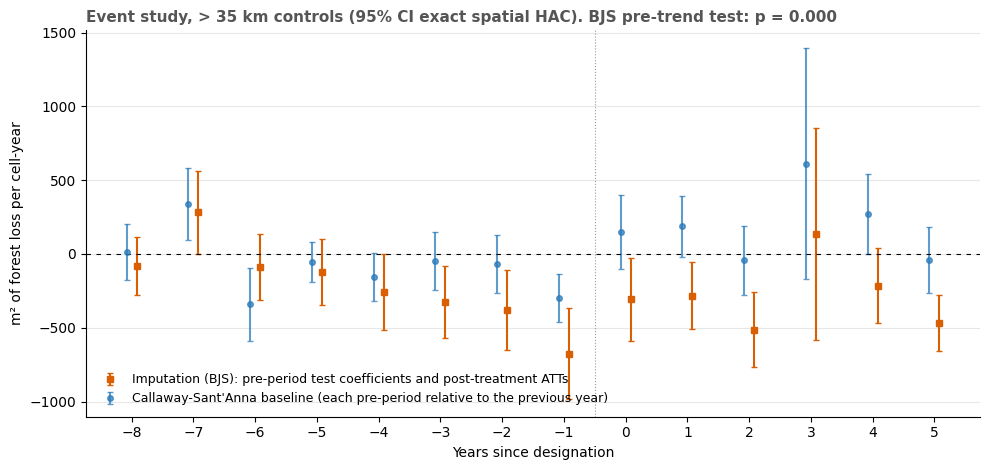

In [6]:
t1 = time.time()
from scipy.stats import chi2
K_PRE = 8
un = long.loc[long['D'] == 0, ['cell', 'year', 'y', 'g']].copy()          # untreated observations only
# cells with a single untreated year (mostly cohort 2002) are singletons: their cell effect absorbs the observation, so they
# carry no information on the deltas; pyfixest drops them, so they are dropped here explicitly (identical estimates)
un = un[un.groupby('cell')['y'].transform('size') >= 2]
rel = un['year'].to_numpy().astype(int) - un['g'].to_numpy().astype(int)
is_tr = un['g'].to_numpy() > 0
pre_cols = [f'pre{k}' for k in range(1, K_PRE + 1)]
for k, c in zip(range(1, K_PRE + 1), pre_cols):
    un[c] = (is_tr & (rel == -k)).astype(np.int8)
fit_pt = pf.feols('y ~ ' + ' + '.join(pre_cols) + ' | cell + year', data=un, vcov={'CRV1': 'cell'})
b_pt = fit_pt.coef()[pre_cols].to_numpy()
Xd = np.asarray(fit_pt._X); u_pt = np.asarray(fit_pt._u_hat).ravel()
assert Xd.shape == (len(un), K_PRE), 'pyfixest dropped rows'
XtX_inv = np.linalg.inv(Xd.T @ Xd)
cells_pt = un['cell'].to_numpy()
Sc = np.column_stack([np.bincount(cells_pt, weights=Xd[:, k] * u_pt, minlength=n_cells) for k in range(K_PRE)])
Psi_pt = Sc @ XtX_inv                         # delta_hat - delta ~ sum_i Psi_i (per-cell influence)
V_hac = np.empty((K_PRE, K_PRE))
for k in range(K_PRE):
    V_hac[k, k] = lattice.variance(Psi_pt[:, k])
for k in range(K_PRE):
    for l in range(k + 1, K_PRE):
        V_hac[k, l] = V_hac[l, k] = (lattice.variance(Psi_pt[:, k] + Psi_pt[:, l]) - lattice.variance(Psi_pt[:, k] - Psi_pt[:, l])) / 4
V_cell = Psi_pt.T @ Psi_pt
wald_hac = float(b_pt @ np.linalg.solve(V_hac, b_pt)); wald_cell = float(b_pt @ np.linalg.solve(V_cell, b_pt))
pretrend = pd.DataFrame({'event_time': [-k for k in range(1, K_PRE + 1)], 'att': b_pt,
                         'se_hac': np.sqrt(np.diag(V_hac)), 'se_analytic': np.sqrt(np.diag(V_cell))}).sort_values('event_time')
pretrend.to_csv(TABLE_DIR / f'14_imputation_pretrend_buffer35_{RUN_TAG}.csv', index=False)
pt_test = pd.DataFrame([{'test': 'BJS pre-trend, k = 1..8', 'wald_hac': wald_hac, 'df': K_PRE, 'p_hac': float(chi2.sf(wald_hac, K_PRE)),
                         'wald_cell': wald_cell, 'p_cell': float(chi2.sf(wald_cell, K_PRE))}])
pt_test.to_csv(TABLE_DIR / f'14_imputation_pretrend_test_buffer35_{RUN_TAG}.csv', index=False)
display(pretrend.round(1)); display(pt_test.round(4))
print(f'[{time.time() - t1:.0f}s]')

# imputation event study: pre-periods (BJS) and post-periods (imputation ATTs), with CS baseline for comparison
ev_cs = pd.read_csv(NB12_EVENTS).query("control_group == 'buffer_35' and spec == 'baseline' and event_time >= -8 and event_time <= 5")
fig, ax = plt.subplots(figsize=(10, 4.8))
imp_all = pd.concat([pretrend, imp_events], ignore_index=True).sort_values('event_time')
ax.errorbar(imp_all['event_time'] + 0.08, imp_all['att'], yerr=1.96 * imp_all['se_hac'], fmt='s', color='#d95f02', capsize=2.5,
            markersize=5, label='Imputation (BJS): pre-period test coefficients and post-treatment ATTs')
ax.errorbar(ev_cs['event_time'] - 0.08, ev_cs['att'], yerr=1.96 * ev_cs['se_hac'], fmt='o', color='#2b7bba', capsize=2, markersize=4,
            alpha=0.75, label="Callaway-Sant'Anna baseline (each pre-period relative to the previous year)")
ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5))); ax.axvline(-0.5, color='#999999', linewidth=0.8, linestyle=':')
ax.set_xticks(range(-8, 6)); ax.set_xlabel('Years since designation'); ax.set_ylabel('m² of forest loss per cell-year')
ax.set_title(f"Event study, > 35 km controls (95% CI exact spatial HAC). BJS pre-trend test: p = {pt_test['p_hac'].iloc[0]:.3f}",
             loc='left', color='#555555', fontsize=11, weight='bold')
ax.grid(True, axis='y', color='#e7e7e7'); ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc='lower left')
fig.tight_layout(); fig.savefig(FIG_DIR / f'14_imputation_event_study_buffer35_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

### HAC cutoff: imputation and TWFE

Same check as notebook 13 for Callaway-Sant'Anna: the spatial-HAC SE by Bartlett cutoff. A SE still rising at 35 km means the 35 km SEs are lower bounds.

In [7]:
t1 = time.time()
CUTOFFS_KM = [0, 10, 20, 35, 50, 75, 100]
psi_cut = {'Imputation (BJS)': psi_imp, 'TWFE': psi_store['TWFE (notebook 12)']}
rows = []
for c in CUTOFFS_KM:
    lat_c = None if c == 0 else (lattice if c == HAC_CUTOFF_KM else ConleyLattice(xy[:, 0], xy[:, 1], cutoff_km=float(c)))
    for name, psi in psi_cut.items():
        se = float(np.sqrt(np.sum(psi ** 2))) if c == 0 else lat_c.se(psi)
        rows.append({'estimator': name, 'cutoff_km': c, 'se': se})
cut = pd.DataFrame(rows)
att_of = {'Imputation (BJS)': att_imp, 'TWFE': results[0]['att']}
cut['z'] = cut.apply(lambda r: att_of[r['estimator']] / r['se'], axis=1)
cut['p'] = cut['z'].map(normal_p)
cut.to_csv(TABLE_DIR / f'14_hac_cutoff_sensitivity_{RUN_TAG}.csv', index=False)
display(cut.pivot(index='cutoff_km', columns='estimator', values=['se', 'p']).round(3))
print(f'[{time.time() - t1:.0f}s]')

se                         p       
estimator Imputation (BJS)     TWFE Imputation (BJS)   TWFE
cutoff_km                                                  
0                   15.499   18.762            0.000  0.000
10                  60.352   75.179            0.000  0.000
20                  94.151  114.652            0.000  0.001
35                 127.366  154.124            0.001  0.012
50                 146.690  179.360            0.003  0.030
75                 165.154  208.409            0.009  0.062
100                177.264  231.807            0.015  0.093

[13s]


## Summary: same sample, five estimators

,estimator,att,se_hac,se_analytic,p,sig,pct_of_control_mean
0,Callaway-Sant'Anna baseline (R did),-103.6,124.2,22.3,0.4,,-7.9
1,Callaway-Sant'Anna DR (R did),-125.2,270.5,63.7,0.6,,-9.6
2,TWFE (notebook 12),-389.1,154.1,18.8,0.0,*,-29.8
3,TWFE + baseline-characteristic x year effects,-231.4,226.9,24.4,0.3,,-17.7
4,Imputation (BJS / two-stage DiD),-429.9,127.4,15.5,0.0,***,-32.9


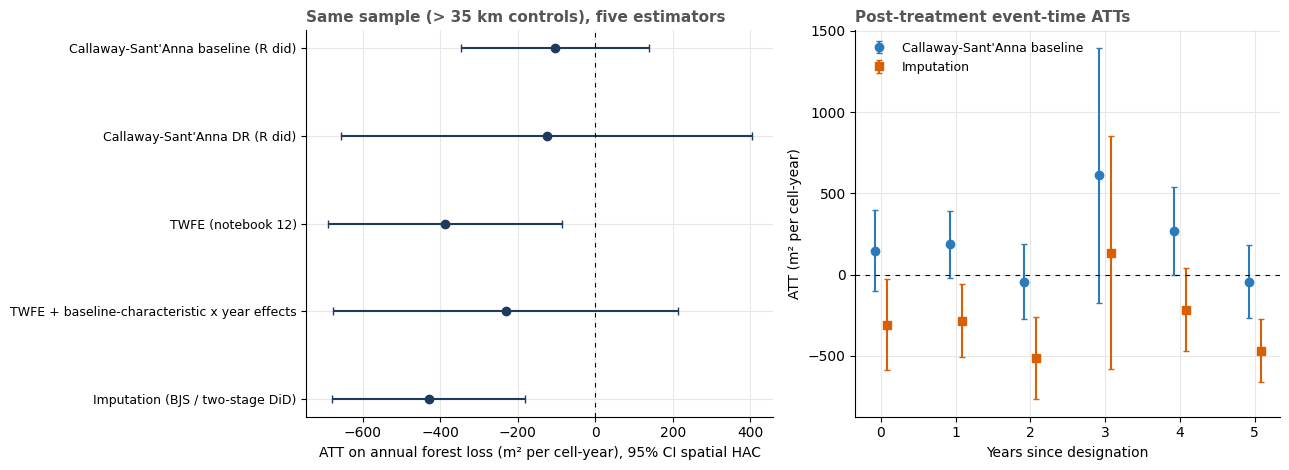

In [8]:
cs = pd.read_csv(NB12_OVERALL).query("control_group == 'buffer_35' and spec in ['baseline', 'dr_geography']")
cs = cs.assign(estimator=cs['spec'].map({'baseline': "Callaway-Sant'Anna baseline (R did)", 'dr_geography': "Callaway-Sant'Anna DR (R did)"}))
summary = pd.concat([cs[['estimator', 'att', 'se_hac', 'se_analytic', 'p', 'sig']], pd.DataFrame(results)], ignore_index=True)
summary['sig'] = summary['sig'].fillna('')
summary['pct_of_control_mean'] = 100 * summary['att'] / float(Y[ctrl].mean())
display(summary.round(1))
summary.to_csv(TABLE_DIR / f'14_twfe_diagnostics_buffer35_{RUN_TAG}.csv', index=False)
imp_events.to_csv(TABLE_DIR / f'14_imputation_event_time_buffer35_{RUN_TAG}.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = axes[0]
yy = np.arange(len(summary))[::-1]
ax.errorbar(summary['att'], yy, xerr=1.96 * summary['se_hac'], fmt='o', color='#1f3a5f', capsize=3)
ax.axvline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax.set_yticks(yy); ax.set_yticklabels(summary['estimator'], fontsize=9)
ax.set_xlabel('ATT on annual forest loss (m² per cell-year), 95% CI spatial HAC')
ax.set_title('Same sample (> 35 km controls), five estimators', loc='left', color='#555555', fontsize=11, weight='bold')
ax = axes[1]
ev = pd.read_csv(NB12_EVENTS).query("control_group == 'buffer_35' and spec == 'baseline' and event_time >= 0 and event_time <= 5")
ax.errorbar(ev['event_time'] - 0.08, ev['att'], yerr=1.96 * ev['se_hac'], fmt='o', color='#2b7bba', capsize=2, label="Callaway-Sant'Anna baseline")
ax.errorbar(imp_events['event_time'] + 0.08, imp_events['att'], yerr=1.96 * imp_events['se_hac'], fmt='s', color='#d95f02', capsize=2, label='Imputation')
ax.axhline(0, color='black', linewidth=0.8, linestyle=(0, (4, 5)))
ax.set_xlabel('Years since designation'); ax.set_ylabel('ATT (m² per cell-year)')
ax.set_title('Post-treatment event-time ATTs', loc='left', color='#555555', fontsize=11, weight='bold')
ax.legend(frameon=False, fontsize=9)
for a in axes:
    a.grid(True, color='#e7e7e7'); a.spines['top'].set_visible(False); a.spines['right'].set_visible(False)
fig.tight_layout(); fig.savefig(FIG_DIR / f'14_twfe_diagnostics_buffer35_{RUN_TAG}.png', dpi=220, bbox_inches='tight'); plt.show()

### Reading the results

* **TWFE + characteristic x year effects close to Callaway-Sant'Anna**: the TWFE gap came from different trends by landscape type that TWFE's common year effects ignore.
* **Imputation close to Callaway-Sant'Anna, TWFE far**: the gap comes from TWFE's comparisons and weighting (already-treated cells as implicit controls, variance weights), not from the sample or the controls.
* **Imputation close to TWFE**: the gap comes from the counterfactual using all pre-treatment years (imputation, TWFE) rather than only *g*-1 (Callaway-Sant'Anna), i.e. from pre-trends; then the anticipation / pre-trend question of notebooks 12-13 is the crux.